<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 15 · In production</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Monitoring a forecast means watching five things: accuracy against a baseline on the same weeks, bias, interval coverage, the health of the inputs, and how far the forecast moves at each refit. Only the input and stability checks run before actuals arrive. On 200 synthetic weekly histories in which volume creeps up by a further $0.5$ t/week every week, a CUSUM chart on the forecast errors, set to raise $0.77$ false alarms a season, caught the creep within 26 weeks in $86\%$ of histories, against $20\%$ when there was no creep. A tracking signal with a similar false-alarm rate caught $63\%$, against $29\%$. Comparing the model's rolling error with seasonal naive's did no better than chance, because the baseline got worse too. Errors of overlapping four-week-ahead forecasts are correlated, so textbook alarm limits fire too often. Afterwards you should be able to choose what to monitor, run a CUSUM on forecast errors, set its limit by injecting a ramp into your own backtest errors, and say who acts when it fires.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
P, H = 52, 4  # weeks per season; forecast horizon in weeks
FIT, START, CHANGE, END = 2 * P, 3 * P, 5 * P, 7 * P  # fit on seasons 1-2, calibrate on 3, monitor 4-7; bias from week 260

## What to watch

A forecast in production fails in ways a backtest never saw: a feed stops, the process drifts, as in [Retraining and drift](../retraining-and-drift/retraining_and_drift.ipynb), or a refit moves every number. Five things to watch:

| Watch | Measure | Known |
|---|---|---|
| **Accuracy** | rolling MAE, and skill against a baseline on the same weeks | $h + d$ weeks after issue |
| **Bias** | running mean error, tracking signal, CUSUM | $h + d$ weeks after issue |
| **Coverage** | share of actuals inside each interval | $h + d$ weeks after issue |
| **Inputs** | missing, late or out-of-range values; changed columns or units | at issue |
| **Stability** | refit jump $J$; how much the forecast for one week changes between issues | at issue |

Here $h$ is the horizon and $d$ the data latency, in weeks. Skill, $1 - \text{MAE}_\text{model}/\text{MAE}_\text{baseline}$, is from [Baselines first](../baselines-first.qmd), bias from [Which metric](../which-metric.qmd), coverage from [Pinball loss and quantiles](../pinball-loss-and-quantiles.qmd), and $J$, the mean change in the forecast at a refit, from the previous module.

Only the last two rows can stop a bad forecast before anyone uses it: check that every input arrived on time, inside its training range, with the expected columns and units. For the first three, the weekly question is whether the latest errors are bad luck or a change; the rest of this module asks it of bias.

## Signal or noise

The data are **synthetic**, from fixed seeds: seven seasons of weekly volume at a packhouse, the series of [Leakage](../leakage/leakage.ipynb) (the code below gives the equation). From week 260, the start of season 6, the volume rises by a further $0.5$ t/week every week, until after $15/0.5 = 30$ weeks it sits $15$ t/week higher, as when a new customer ramps up orders.

The model, a ridge regression fitted once on seasons 1 and 2, forecasts $h = 4$ weeks ahead from the last three weeks' volume, the target's week a season earlier, and the week of the season; season-3 errors set the charts' scale. Errors are actual minus forecast, $e_t = y_t - \hat{y}_t$ (positive means under-forecast), indexed by target week.

In [2]:
def simulate(seed, creep=0.5, cap=15):  # synthetic weekly volume, t/week
    rng = np.random.default_rng(seed)
    t = np.arange(END)
    level = 40 + 25 * np.clip(np.sin(2 * np.pi * (t % P - 13) / P), 0, None)
    extra = np.clip(creep * (t - CHANGE + 1), 0, cap)  # the creep, from week 260
    noise = np.zeros(END)
    for i in range(1, END):  # AR(1): a high week tends to follow a high week
        noise[i] = 0.6 * noise[i - 1] + rng.normal(0, 4)
    return pd.Series(level + extra + noise)


def errors(seed, h=H, **kw):
    """Errors (actual - forecast, t/week) by target week: a ridge model fitted once, and seasonal naive."""
    y = simulate(seed, **kw)
    t = np.arange(END)
    d = pd.DataFrame({
        "y_t": y, "y_t-1": y.shift(1), "y_t-2": y.shift(2),
        "same_week_last_season": y.shift(P - h),  # y[t+h-52], known at t
        "sin": np.sin(2 * np.pi * (t + h) / P), "cos": np.cos(2 * np.pi * (t + h) / P),
        "target": y.shift(-h),
    }).set_index(t + h).dropna()  # one row per target week
    X = d.drop(columns="target")
    model = Ridge().fit(X.loc[: FIT - 1], d.target.loc[: FIT - 1])
    d = d.loc[FIT:]
    return pd.DataFrame({"model": d.target - model.predict(X.loc[FIT:]),
                         "seasonal naive": d.target - d.same_week_last_season})

In [3]:
e = errors(seed=0)
period = pd.cut(e.index, [FIT, START, CHANGE, 6 * P, END], right=False,
                labels=["season 3 (calibration)", "seasons 4-5", "season 6", "season 7"])
cols = {"model mean error": e.model, "model MAE": e.model.abs(), "seasonal naive MAE": e["seasonal naive"].abs()}
pd.DataFrame(cols).groupby(period, observed=True).mean().round(1)  # t/week; positive mean error = under-forecast

,model mean error,model MAE,seasonal naive MAE
season 3 (calibration),-0.4,4.1,5.2
seasons 4-5,-0.5,4.6,5.0
season 6,7.1,7.7,10.0
season 7,9.8,9.8,7.8


In seasons 4 and 5 the model is nearly unbiased and slightly better than seasonal naive, a skill of $1 - 4.6/5.0 = 0.08$. In season 6 its mean error is $+7.1$ t/week, yet its skill rises to $1 - 7.7/10.0 = 0.23$: seasonal naive repeats last season, which had no creep, and suffers more. Skill says whether a model is worth running, not whether it has changed.

Three checks watch the errors week by week:

- **Rolling MAE against the baseline.** Alarm when the model's 8-week MAE first exceeds seasonal naive's.
- **Tracking signal.** The running sum of errors divided by a typical error size, the mean absolute deviation (MAD)[^1]:

$$T_t = \frac{\sum_{i=t_0}^{t} e_i}{M_t}, \qquad M_t = \alpha \lvert e_t \rvert + (1 - \alpha) M_{t-1}$$

where $T_t$ is the tracking signal in MADs, $t_0$ the first week after the last alarm, and $M_t$ the MAD in t/week, smoothed with weight $\alpha = 0.1$ and started at the season-3 MAD. It alarms when $\lvert T_t \rvert > L_\text{TS}$, here $4$.
- **CUSUM.** A running total that forgets any week that looks normal. Each week it adds the error, in standard deviations, minus an allowance $K$, and never drops below zero; one total watches for under-forecasts, another for over-forecasts:

$$S^{+}_t = \max\!\big(0,\ S^{+}_{t-1} + z_t - K\big), \qquad S^{-}_t = \max\!\big(0,\ S^{-}_{t-1} - z_t - K\big), \qquad z_t = e_t / \hat{\sigma}$$

where $\hat{\sigma}$ is the standard deviation of the season-3 errors (t/week), $z_t$ the error in units of $\hat{\sigma}$, and $S^{\pm}_t$ the two totals in the same units. It alarms when either exceeds a limit $L_\text{C}$. The NIST handbook gives a rule of thumb it attributes to Montgomery: an allowance of half the shift to be detected and a limit of about 4 or 5[^2]. For a shift of one standard deviation, $K = 0.5$ and $L_\text{C} = 5$.

With no bias, the tracking signal's sum wanders like a random walk and eventually crosses any limit; the allowance stops the CUSUM doing the same. Both restart after an alarm, as if someone had looked and found nothing.

In [4]:
def tracking_signal(e, mad, limit=4, alpha=0.1):
    """Alarm when |errors summed since the last alarm| exceeds `limit` smoothed MADs."""
    path, alarms, total = [], [], 0.0
    for week, x in e.items():
        total += x
        mad = alpha * abs(x) + (1 - alpha) * mad
        path.append(total / mad)
        if abs(total) > limit * mad:
            alarms.append((week, np.sign(total)))
            total = 0.0  # someone investigates, the count restarts
    return pd.Series(path, e.index), alarms


def cusum(e, sigma, allowance=0.5, limit=5):
    """Two-sided tabular CUSUM on errors in units of sigma; restarts after each alarm."""
    path, alarms, hi, lo = [], [], 0.0, 0.0
    for week, x in e.items():
        hi, lo = max(0.0, hi + x / sigma - allowance), max(0.0, lo - x / sigma - allowance)
        path.append(hi if hi >= lo else -lo)
        if max(hi, lo) > limit:
            alarms.append((week, 1 if hi > limit else -1))
            hi = lo = 0.0
    return pd.Series(path, e.index), alarms


def worse_than_baseline(e, n=8):
    """Alarm when the model's n-week MAE first rises above seasonal naive's on the same weeks."""
    mae = e.abs().rolling(n).mean()
    bad = mae.model > mae["seasonal naive"]
    return mae, [(week, 0) for week in bad.index[bad & ~bad.shift(1, fill_value=False)]]


def run_all(e, ts_limit=4, cusum_limit=5, window=8):
    calib, live = e.loc[: START - 1], e.loc[START:]
    return {"rolling MAE vs baseline": worse_than_baseline(live, window),
            "tracking signal": tracking_signal(live.model, calib.model.abs().mean(), ts_limit),
            "CUSUM": cusum(live.model, calib.model.std(), limit=cusum_limit)}


def score(alarms):  # false alarms before week 260; weeks from 260 to the first upward alarm
    false = sum(week < CHANGE for week, _ in alarms)
    caught = [week - CHANGE for week, sign in alarms if week >= CHANGE and sign >= 0]
    return false, caught[0] if caught else np.nan

On history 0, each check's false alarms before the creep and its first alarm after week 260. The tracking signal's catch in week 0 is luck, as the figure shows:

In [5]:
runs = run_all(e)
pd.DataFrame([score(alarms) for _, alarms in runs.values()], index=runs.keys(),
             columns=["false alarms, seasons 4-5", "weeks to first alarm after 260"])

,"false alarms, seasons 4-5",weeks to first alarm after 260
rolling MAE vs baseline,7,12
tracking signal,13,0
CUSUM,6,22


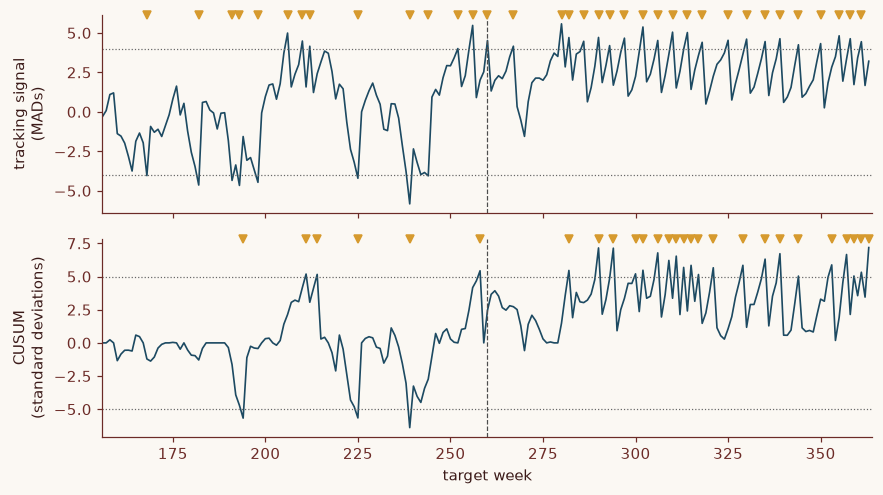

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
for ax, name, limit, unit in zip(axes, ["tracking signal", "CUSUM"], [4, 5], ["MADs", "standard deviations"]):
    path, alarms = runs[name]
    ax.plot(path, color=C1, lw=1.1)
    for y in (limit, -limit):
        ax.axhline(y, color="0.4", lw=0.8, ls=":")
    ax.axvline(CHANGE, color="0.3", lw=0.8, ls="--")
    for week, _ in alarms:  # one triangle per alarm
        ax.plot(week, 1, marker="v", color=C2, ms=5, transform=ax.get_xaxis_transform(), clip_on=False)
    ax.set_ylabel(f"{name}\n({unit})")
axes[1].set(xlabel="target week", xlim=(START, END))
fig.tight_layout()
plt.show()

<strong>Figure 1 | Two bias checks on one history.</strong> Synthetic history 0; the creep starts at the dashed line. Triangles mark alarms, dotted lines the limits. Bottom: the larger of $S^{+}$ and $S^{-}$, the downward one drawn negative. Nobody acts on the alarms, so they keep firing.

The tracking signal fired in the creep's first week, when it was $0.5$ t/week, an eighth of the season-3 MAE of $4.1$; with 13 false alarms before, it fired about every $104/13 = 8$ weeks anyway. The CUSUM fired 22 weeks in, when the creep had reached $0.5 \times 23 = 11.5$ t/week.

## False alarms against delay

A fair test runs each detector on many histories, with and without the creep, and asks how often it raises an upward alarm within 26 weeks of week 260. A detector is useful only if the first share is well above the second.

Textbook limits assume independent errors, but forecasts four weeks ahead issued a week apart share three weeks of unseen noise. The correlation between errors, by horizon:

In [7]:
histories = {creep: [errors(seed, creep=creep) for seed in range(200)] for creep in (0.5, 0.0)}
calm = {h: [errors(seed, h=h, creep=0).model.loc[START : CHANGE - 1] for seed in range(200)] for h in (1, 4, 8)}
pd.DataFrame({f"{k} weeks apart": {f"h = {h}": np.mean([x.autocorr(k) for x in xs]) for h, xs in calm.items()}
              for k in (1, 4)}).round(2)  # mean correlation between model errors, seasons 4-5

,1 weeks apart,4 weeks apart
h = 1,0.09,0.06
h = 4,0.62,0.09
h = 8,0.64,0.18


At $h = 4$, errors a week apart have an average correlation of $0.62$, against $0.09$ at $h = 1$; at $h = 8$ it is still $0.18$ four weeks apart. Correlated errors come in runs, so a running sum swings wider and crosses a textbook limit more often. Each detector, on 200 histories with the creep and the same 200 without:

In [8]:
SETTINGS = {"rolling MAE vs baseline": ("window", [8, 26]), "tracking signal": ("ts_limit", [4, 16]),
            "CUSUM": ("cusum_limit", [5, 8, 12])}
out = {}
for name, (arg, values) in SETTINGS.items():
    for v in values:
        s = {c: np.array([score(run_all(e, **{arg: v})[name][1]) for e in hs]) for c, hs in histories.items()}
        out[f"{name}, {arg.split('_')[-1]} {v}"] = {"false alarms per season": s[0.5][:, 0].mean() / 2,
                                                   "caught in 26 weeks": np.mean(s[0.5][:, 1] < 26),
                                                   "fired in 26 weeks, no creep": np.mean(s[0.0][:, 1] < 26)}
pd.DataFrame(out).T.round(2)

,false alarms per season,caught in 26 weeks,"fired in 26 weeks, no creep"
"rolling MAE vs baseline, window 8",2.82,0.81,0.90
"rolling MAE vs baseline, window 26",1.10,0.43,0.49
"tracking signal, limit 4",6.71,1.00,0.78
"tracking signal, limit 16",0.88,0.63,0.29
"CUSUM, limit 5",1.72,0.96,0.37
"CUSUM, limit 8",0.77,0.86,0.20
"CUSUM, limit 12",0.31,0.70,0.10


At similar false-alarm rates the CUSUM separates the two better: at $L_\text{C} = 8$, $0.77$ false alarms a season, it catches $86\%$ against $20\%$ without the creep; the tracking signal at $L_\text{TS} = 16$, $0.88$, catches $63\%$ against $29\%$. At $L_\text{TS} = 4$ the tracking signal fires within 26 weeks in $100\%$ of histories with the creep and $78\%$ without: it barely tells them apart. The rolling check fires more often without the creep than with it, $90\%$ against $81\%$ over 8 weeks, because the creep hurts the baseline more than the model. Keep it for the question "is this model still worth running?" and use a bias chart for change.

No row is free: raising the CUSUM limit from 5 to 12 cuts false alarms from $1.72$ to $0.31$ a season and the share caught from $96\%$ to $70\%$. Choose by what a false alarm costs (an analyst's afternoon) against a missed creep (weeks of wrong orders).

Your own data hold one history: replay the detector on your backtest errors to count false alarms, and add a ramp to the same errors from many start weeks to count catches. A helper to copy:

In [9]:
# Reusable: replay a detector on your own in-control backtest errors.
def tune(e, detect, limits, ramp=lambda k: np.clip(0.5 * (k + 1), 0, 15), within=26):
    """detect(errors, limit) -> [(week, sign)]. Returns false alarms per season on `e` as it is, and the
    share of start weeks (every 4th) at which `ramp`, added from that week on, raises an upward alarm in time."""
    out = {}
    for limit in limits:
        starts = e.index[:-within:4]
        hits = [any(s <= w < s + within and sign > 0 for w, sign in detect(e + ramp(e.index - s), limit)) for s in starts]
        out[limit] = {"false alarms per season": len(detect(e, limit)) / (len(e) / P), "caught in 26 weeks": np.mean(hits)}
    return pd.DataFrame(out).T

In [10]:
e0 = histories[0.0][0].model  # history 0 without the creep: seasons 4-7 serve as backtest errors
sigma = e0.loc[: START - 1].std()
tune(e0.loc[START:], lambda e, limit: cusum(e, sigma, limit=limit)[1], [5, 8, 12]).round(2)

,false alarms per season,caught in 26 weeks
5,2.25,1.00
8,1.25,1.00
12,0.00,0.93


On history 0 alone, the recipe puts $L_\text{C} = 12$ at no false alarms in four seasons and a $93\%$ catch rate, more optimistic than the 200-history test's $0.31$ and $70\%$. Four seasons hold few false alarms, and an injected ramp skips what the model absorbs: in season 6 the creep averaged $(30 \times 7.75 + 22 \times 15)/52 = 10.8$ t/week, but the model's mean error rose by only $7.1 - (-0.5) = 7.6$. Use the recipe to rank limits, then leave a margin.

Size the ramp by what matters to the business: the smallest change worth acting on, such as a customer ramping up or a new field coming into harvest. The ridge model, $h = 4$ and this creep are one design, and error correlation changes with the horizon, so rerun the tuning on your own backtest errors at each horizon you issue. A next step for strongly seasonal harvests: divide each error by the backtest MAE for its week of the season, so the peak does not fire on its own.

## Alerts that get acted on

An alert nobody owns is noise. Each needs an owner, a first action, and a false-alarm rate the owner has agreed to. Example limits, to set from a backtest:

| Alert | Fires when | Owner and first action |
|---|---|---|
| **Inputs** | an input is missing, late, out of range, or its schema changed | data engineer: hold, or issue from the last good inputs, flagged |
| **Bias** | the CUSUM on errors crosses its limit | forecast owner: find the cause; recalibrate or refit |
| **Coverage** | an 80% interval covers under $64\%$ of the last 26 weeks | forecast owner: recalibrate the intervals |
| **Accuracy** | skill below zero for a season | forecast owner: issue the baseline meanwhile |
| **Stability** | a refit's $J$ is far above its usual range | release reviewer: hold the release |

The coverage limit is two standard deviations of a 26-week share below $80\%$: $80 - 2 \times 100\sqrt{0.8 \times 0.2 / 26} = 64.3\%$. Misses in runs make the share noisier; lower the limit if it fires too often.

**When a bias alarm fires**, check the inputs first: a late feed or a changed unit can look like a creep. Then see where the errors moved. At every horizon and in every segment, it is a level shift: recalibrate or refit, as in [Retraining and drift](../retraining-and-drift/retraining_and_drift.ipynb). Only in some weeks of the season or some segments: find what changed there first.

Show error and bias per horizon and segment, since an average hides the failing slice, and log what each alarm found.

## Key takeaways

- Check inputs and stability at issue; nothing else fires before the forecast is used.
- Track bias apart from skill: a model can gain skill while going wrong, if its baseline goes wrong faster.
- Chart bias with a CUSUM, whose allowance drains noise, rather than a running sum.
- Set limits on backtest errors at each horizon you issue, with a ramp the size of the smallest change worth acting on.
- Give every alert an owner and a first action: for bias, check inputs, then where errors moved, then recalibrate or refit.

## References

[^1]: Trigg's paper starts from this signal, which Brown had examined in detail. Trigg, D. W. Monitoring a forecasting system. *Oper. Res. Q.* **15**, 271–274 (1964). https://doi.org/10.1057/jors.1964.48
[^2]: Guthrie, W. F. *NIST/SEMATECH e-Handbook of Statistical Methods* (NIST Handbook 151), Section 6.3.2.3 (National Institute of Standards and Technology, 2020). https://doi.org/10.18434/M32189

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/retraining-and-drift/retraining_and_drift.html"><span>Previous</span>Retraining and drift</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a></div>
<!-- CURRICULUM_FOOTER_END -->